# Practical No. 05: Image Generation using Pretrained Stable Diffusion

**Aim:** Implement a pretrained Stable Diffusion model using Hugging Face Diffusers to generate images from text prompts, then study how inference steps, guidance scale, and sampling methods affect image quality.


## 1. Install required libraries

In [2]:
!pip -q install --upgrade diffusers transformers accelerate safetensors

## 2. Import libraries and check hardware

In [3]:
import os, gc, time, json
import torch
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display

from diffusers import (
    StableDiffusionPipeline,
    DDIMScheduler,
    EulerDiscreteScheduler,
    DPMSolverMultistepScheduler,
)

device = "cuda" if torch.cuda.is_available() else "cpu"
dtype = torch.float16 if device == "cuda" else torch.float32

print("PyTorch:", torch.__version__)
print("Device:", device)
if device == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: GPU not detected. Enable a GPU runtime for practical generation speed.")

PyTorch: 2.11.0+cu130
Device: cuda
GPU: Tesla T4


## 3. Load the pretrained Stable Diffusion model

Stable Diffusion is a latent diffusion model. It starts with random noise in a compressed latent space and repeatedly denoises that latent according to the text prompt. The VAE decoder converts the final latent into an image.

In [4]:
MODEL_ID = "stable-diffusion-v1-5/stable-diffusion-v1-5"

pipe = StableDiffusionPipeline.from_pretrained(
    MODEL_ID,
    torch_dtype=dtype,
    safety_checker=None,  # kept disabled for compatibility in this educational notebook
    requires_safety_checker=False,
)
pipe = pipe.to(device)
pipe.enable_attention_slicing()

print("Model loaded successfully!")

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 13 files:   0%|          | 0/13 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Model loaded successfully!


## 4. Generate the first image



  0%|          | 0/30 [00:00<?, ?it/s]

Generation time: 8.6 seconds


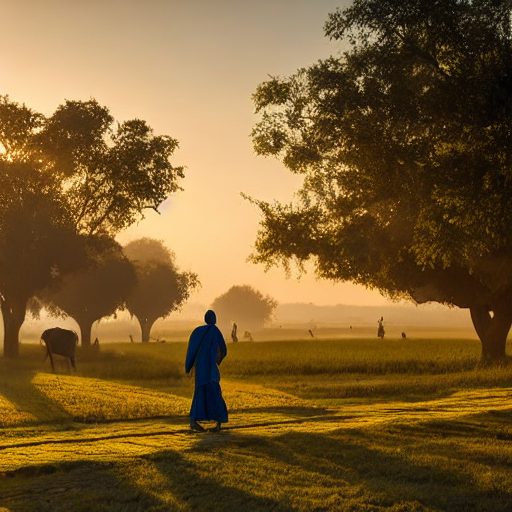

In [5]:
prompt = "A beautiful traditional Indian village at sunrise, green fields, a farmer walking on a path, cinematic lighting, highly detailed digital art"
negative_prompt = "blurry, low quality, distorted, text, watermark"

SEED = 42

def make_generator(seed=SEED):
    # Use a generator on the same device as the pipeline.
    return torch.Generator(device=device).manual_seed(int(seed))

start = time.time()
result = pipe(
    prompt=prompt,
    negative_prompt=negative_prompt,
    num_inference_steps=30,
    guidance_scale=7.5,
    generator=make_generator(SEED),
)
first_image = result.images[0]
print(f"Generation time: {time.time() - start:.1f} seconds")
display(first_image)
os.makedirs("stable_diffusion_outputs", exist_ok=True)
first_image.save("stable_diffusion_outputs/first_generated_image.png")

## 5. Effect of inference steps

Inference steps control how many denoising iterations are performed. More steps can improve refinement up to a point, but they also increase generation time and do not guarantee a better image.

The experiment below uses the same prompt, seed, and guidance scale while changing only the number of steps.

  0%|          | 0/10 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

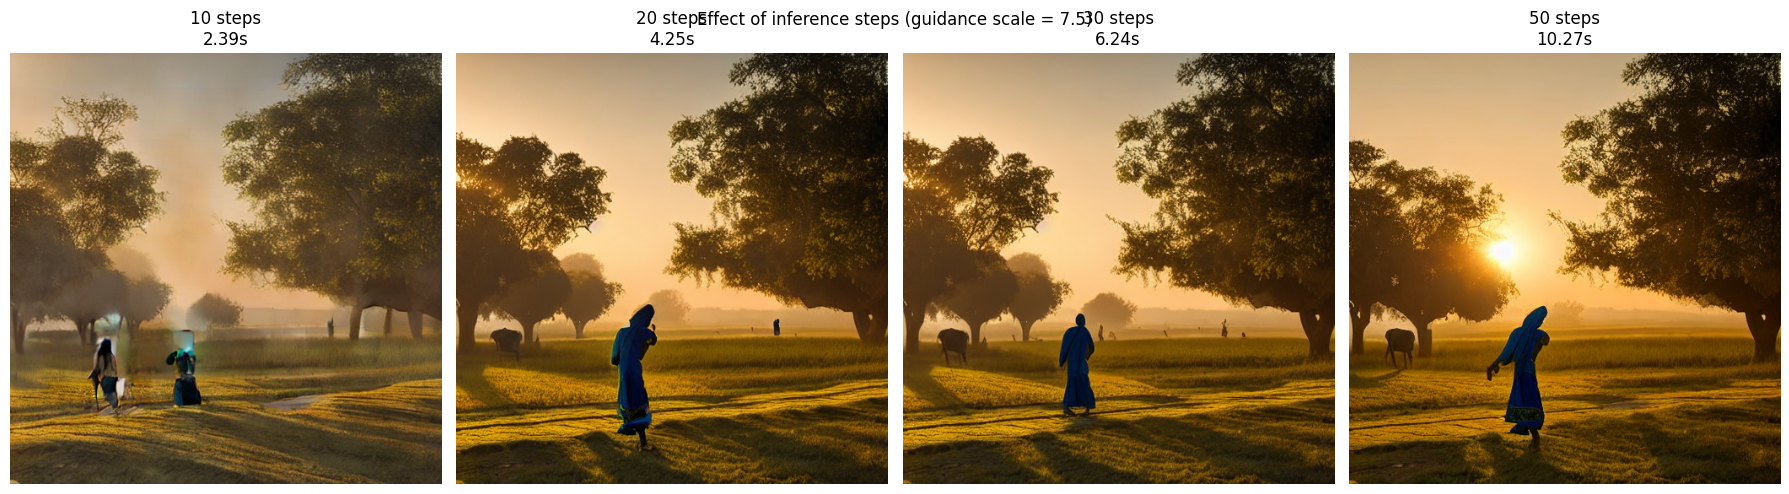

,Inference steps,Generation time (seconds)
0,10,2.39
1,20,4.25
2,30,6.24
3,50,10.27


In [6]:
step_values = [10, 20, 30, 50]
step_images = []
step_times = []

for steps in step_values:
    t0 = time.time()
    img = pipe(
        prompt=prompt,
        negative_prompt=negative_prompt,
        num_inference_steps=steps,
        guidance_scale=7.5,
        generator=make_generator(SEED),
    ).images[0]
    step_times.append(round(time.time() - t0, 2))
    step_images.append(img)

fig, axes = plt.subplots(1, len(step_values), figsize=(18, 5))
for ax, img, steps, seconds in zip(axes, step_images, step_values, step_times):
    ax.imshow(img)
    ax.set_title(f"{steps} steps\n{seconds}s")
    ax.axis("off")
plt.suptitle("Effect of inference steps (guidance scale = 7.5)")
plt.tight_layout()
plt.show()

step_results = pd.DataFrame({
    "Inference steps": step_values,
    "Generation time (seconds)": step_times,
})
display(step_results)
for steps, img in zip(step_values, step_images):
    img.save(f"stable_diffusion_outputs/steps_{steps}.png")

## 6. Effect of guidance scale

Guidance scale controls how strongly the generation is guided by the text prompt. A low value allows more freedom; a higher value generally follows the prompt more strongly. Very high values can produce oversaturated or unnatural results.

Only guidance scale changes in this experiment.

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

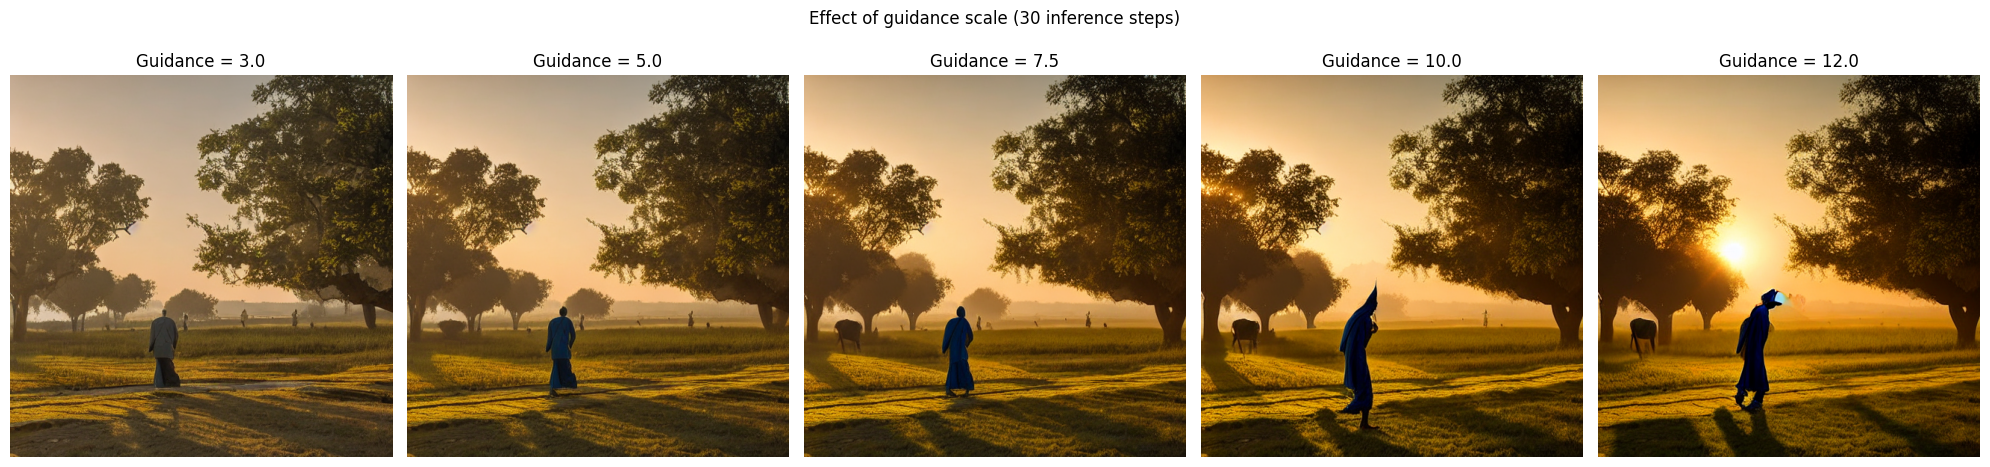

,Guidance scale,Generation time (seconds)
0,3.0,6.50
1,5.0,6.50
2,7.5,6.63
3,10.0,6.80
4,12.0,6.97


In [7]:
guidance_values = [3.0, 5.0, 7.5, 10.0, 12.0]
guidance_images = []
guidance_times = []

for scale in guidance_values:
    t0 = time.time()
    img = pipe(
        prompt=prompt,
        negative_prompt=negative_prompt,
        num_inference_steps=30,
        guidance_scale=scale,
        generator=make_generator(SEED),
    ).images[0]
    guidance_times.append(round(time.time() - t0, 2))
    guidance_images.append(img)

fig, axes = plt.subplots(1, len(guidance_values), figsize=(20, 5))
for ax, img, scale in zip(axes, guidance_images, guidance_values):
    ax.imshow(img)
    ax.set_title(f"Guidance = {scale}")
    ax.axis("off")
plt.suptitle("Effect of guidance scale (30 inference steps)")
plt.tight_layout()
plt.show()

guidance_results = pd.DataFrame({
    "Guidance scale": guidance_values,
    "Generation time (seconds)": guidance_times,
})
display(guidance_results)
for scale, img in zip(guidance_values, guidance_images):
    img.save(f"stable_diffusion_outputs/guidance_{str(scale).replace('.', '_')}.png")

## 7. Compare sampling methods (noise schedulers)

A scheduler determines how the model moves through the denoising process. Here we compare DDIM, Euler, and DPM-Solver using the same prompt, seed, step count, and guidance scale. These are scheduler/sampling-method comparisons, not different trained models.

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

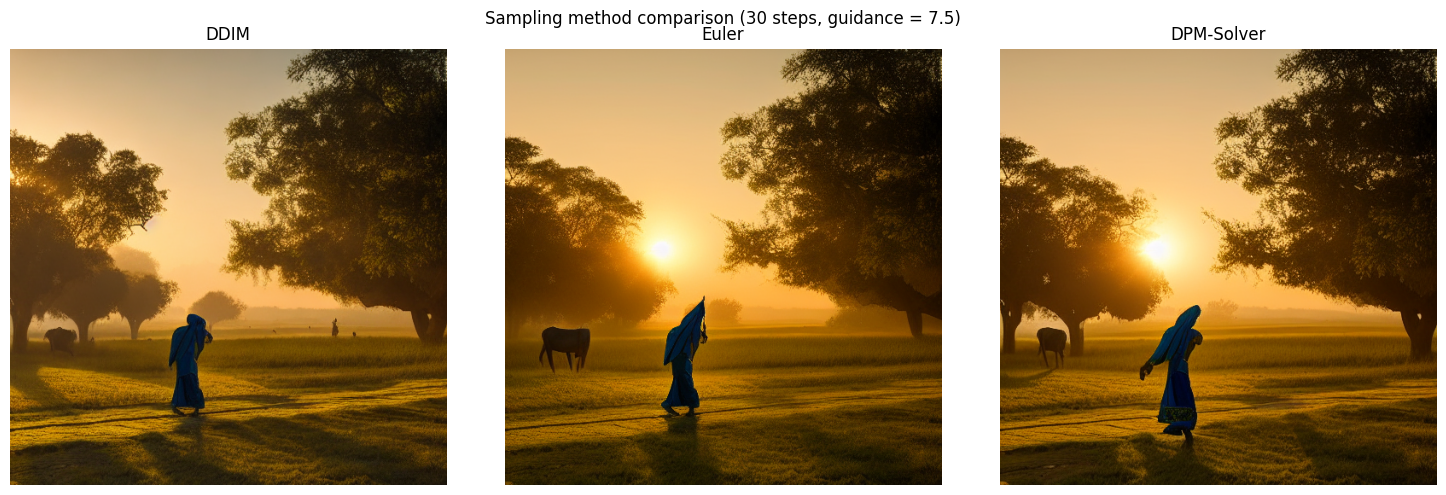

,Scheduler,Generation time (seconds)
0,DDIM,7.05
1,Euler,6.88
2,DPM-Solver,6.99


In [8]:
scheduler_classes = {
    "DDIM": DDIMScheduler,
    "Euler": EulerDiscreteScheduler,
    "DPM-Solver": DPMSolverMultistepScheduler,
}

scheduler_images = {}
scheduler_times = {}

# Keep the original scheduler configuration as the common starting point.
base_config = pipe.scheduler.config

for name, scheduler_class in scheduler_classes.items():
    pipe.scheduler = scheduler_class.from_config(base_config)
    t0 = time.time()
    img = pipe(
        prompt=prompt,
        negative_prompt=negative_prompt,
        num_inference_steps=30,
        guidance_scale=7.5,
        generator=make_generator(SEED),
    ).images[0]
    scheduler_times[name] = round(time.time() - t0, 2)
    scheduler_images[name] = img

fig, axes = plt.subplots(1, len(scheduler_images), figsize=(15, 5))
for ax, (name, img) in zip(axes, scheduler_images.items()):
    ax.imshow(img)
    ax.set_title(name)
    ax.axis("off")
plt.suptitle("Sampling method comparison (30 steps, guidance = 7.5)")
plt.tight_layout()
plt.show()

scheduler_results = pd.DataFrame({
    "Scheduler": list(scheduler_times.keys()),
    "Generation time (seconds)": list(scheduler_times.values()),
})
display(scheduler_results)
for name, img in scheduler_images.items():
    img.save(f"stable_diffusion_outputs/scheduler_{name.lower().replace('-', '_')}.png")

## 8. Save and download all generated images

The images are saved in `stable_diffusion_outputs`. The next cell creates a ZIP archive that can be downloaded from Colab.

In [9]:
import shutil
from google.colab import files

zip_path = shutil.make_archive("stable_diffusion_outputs", "zip", "stable_diffusion_outputs")
print("Created:", zip_path)
files.download(zip_path)

Created: /content/stable_diffusion_outputs.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 9. Result and conclusion

**Result:** A pretrained Stable Diffusion model was loaded using Hugging Face Diffusers and used to generate images from text prompts. Experiments were performed by varying inference steps, guidance scale, and scheduler.

**Conclusion:** The experiments demonstrate that image generation quality and speed depend on inference settings. Increasing inference steps can improve refinement but increases computation time. Guidance scale changes the strength of text-prompt conditioning: moderate values often provide a balance, while very high values may introduce artifacts. Different schedulers produce different denoising trajectories and can change image appearance and speed. The best configuration depends on the prompt and should be selected by comparing generated outputs.

